# Tax Revenue Analysis and a Forecasting Baseline
**Punjab Excise & Taxation Department, public data, 2015-16 to 2023-24**

This notebook documents, step by step, how I analysed the revenue data the department publishes, using Python (pandas, NumPy, matplotlib). It is written for learning: every code cell is explained in plain English, with the **Excel equivalent** and a small **example**.

**Question:** how volatile is provincial revenue, how reliable are the annual targets, and can a simple model forecast it?

**How each section is laid out**
- *What it does:* the idea in plain English.
- *Excel equivalent:* the same task in Excel, if there is one.
- *Example:* a tiny case so the idea is clear before you see the real data.

**Folder structure**
```
project/
├── data/
│   ├── 01_Provincial_Revenue_2015-2024.csv
│   └── 02_District_Vehicle_Registrations_Long.csv
├── charts/                      (created automatically)
└── Tax_Revenue_Analysis.ipynb
```

**Data notes (read before using the results)**
- Revenue: the department's own levy-wise *Target and Recovery* reports. 2016-17 is not yet included, and the 2022-23 and 2023-24 reports are images that were read by hand.
- Vehicle registrations: the department's district-wise quarterly disclosures, 11 of the 16 quarters between July 2021 and June 2025.
- All amounts are in Rs million (revenue) or number of vehicles (registrations).

## 0. Setup

**What it does:** loads the libraries we need and sets two folder names.
- `pandas` works with tables (like Excel, but in code).
- `numpy` does the maths (we use it for regression).
- `matplotlib` draws charts.
- `os.makedirs(..., exist_ok=True)` creates the `charts` folder if it does not exist yet.

**Example:** `import pandas as pd` means "bring in pandas and call it `pd`", so later we can write `pd.read_csv(...)` instead of `pandas.read_csv(...)`.

In [37]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)       # show wide tables on one line
pd.set_option("display.max_columns", None)  # never hide columns

DATA = "."
CHARTS = "charts"
os.makedirs(CHARTS, exist_ok=True)

## 1. Pandas in five minutes (practice with a toy table)

Before the real data, here are the main ideas on a table small enough to check by eye. Run each cell and compare the result with the note under it.

A **DataFrame** is a table: rows and columns, like an Excel sheet.

In [38]:
toy = pd.DataFrame({
    "levy":   ["A", "B", "A", "B"],
    "year":   [2022, 2022, 2023, 2023],
    "amount": [10, 20, 12, 18],
})
toy

,levy,year,amount
0,A,2022,10
1,B,2022,20
2,A,2023,12
3,B,2023,18


**Filtering rows**
*Excel equivalent:* the Filter button.
*Example:* keep only the rows where `levy` is `"A"`. `==` means "is equal to" (a single `=` would assign a value instead).

In [39]:
toy[toy["levy"] == "A"]          # 2 rows: levy A in 2022 and 2023

,levy,year,amount
0,A,2022,10
2,A,2023,12


`isin([...])` means "is any of these". *Example:* keep levies A or B.

In [61]:
toy[toy["levy"].isin(["A", "B"])]  # all 4 rows

,levy,year,amount
0,A,2022,10
1,B,2022,20
2,A,2023,12
3,B,2023,18


In [ ]:
toy[toy["levy"].isin(["A", "B"])]  # all 4 rows

**Group totals** with `groupby`
*Excel equivalent:* a pivot table with one row field and a Sum.
*Example:* total amount per levy. Expected: A = 22, B = 38.

In [62]:
toy.groupby("levy")["amount"].sum()

levy
A    22
B    38
Name: amount, dtype: int64

**Pivot table** with `pivot_table`
*Excel equivalent:* Insert > PivotTable (rows = year, columns = levy, values = amount).

In [42]:
pv = toy.pivot_table(index="year", columns="levy", values="amount", aggfunc="sum")
pv

levy,A,B
year,,
2022,10,20
2023,12,18


**Growth over the previous row** with `pct_change`
*Excel equivalent:* `=(C3-C2)/C2` copied down.
*Example:* levy A went from 10 to 12 (+20%), levy B from 20 to 18 (-10%). The first row has nothing before it, so it shows `NaN` (not a number).

In [43]:
pv.pct_change() * 100

levy,A,B
year,,
2022,NaN,NaN
2023,20.0,-10.0


**Share of the total** with `div`
*Excel equivalent:* each cell divided by its row total.
*Example:* in 2022 levy A is 10 out of 30, so 33.3%. `axis=0` matches the totals to the rows.

In [44]:
pv.div(pv.sum(axis=1), axis=0) * 100

levy,A,B
year,,
2022,33.333333,66.666667
2023,40.000000,60.000000


**Average percentage error (MAPE)**, used later to judge forecasts.
*Example:* actual values are 100 and 200, a model predicts 110 and 180. Errors are 10% and 10%, so MAPE is 10%.

In [45]:
def mape(actual, predicted):
    return (abs(actual - predicted) / actual).mean() * 100

print(mape(np.array([100, 200]), np.array([110, 180])))   # 10.0

10.0


**Pulling numbers out of text** with `str.extract`
*Excel equivalent:* `MID` / `FIND` formulas, or Text to Columns.
*Example:* from `"Jul-Sep 2021 (FY21-22 Q1)"` we want the year `2021` and the quarter number `1`. In the pattern, `\d{4}` means four digits and `\d` means one digit.

In [46]:
label = pd.Series(["Jul-Sep 2021 (FY21-22 Q1)"])
print(label.str.extract(r"(\d{4}) \(")[0].astype(int).iloc[0])   # 2021
print(label.str.extract(r"Q(\d)\)")[0].astype(int).iloc[0])       # 1

2021
1


## 2. Revenue data: load and inspect

**What it does:** reads the CSV into a DataFrame and checks it before any analysis.
- `shape` gives (rows, columns).
- `head()` shows the first rows.
- `info()` shows each column's type and how many values are filled. Some columns have fewer filled values on purpose: a levy that is new has no previous-year figure, and some reports print no target.

**Excel equivalent:** opening the file and looking at it.

In [47]:
rev = pd.read_csv(os.path.join(DATA, "01_Provincial_Revenue_2015-2024.csv"))
print(rev.shape)
rev.head()

(64, 7)


,fiscal_year,levy_name,target_rs_million,achieved_rs_million,achieved_prev_year_rs_million,growth_vs_last_year_%,achievement_vs_target_%
0,2015-16,Motor Vehicle Tax,11202.60,11154.30,9686.50,15.15,99.57
1,2015-16,Property Tax,8660.00,8157.33,7342.72,11.09,94.20
2,2015-16,Excise Duty,2656.80,2656.82,1814.63,46.41,100.00
3,2015-16,Professional Tax,770.00,644.96,619.22,4.16,83.76
4,2015-16,Cotton Fee,260.57,261.46,467.43,-44.06,100.34


In [48]:
rev.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   fiscal_year                    64 non-null     str    
 1   levy_name                      64 non-null     str    
 2   target_rs_million              60 non-null     float64
 3   achieved_rs_million            64 non-null     float64
 4   achieved_prev_year_rs_million  63 non-null     float64
 5   growth_vs_last_year_%          63 non-null     float64
 6   achievement_vs_target_%        57 non-null     float64
dtypes: float64(5), str(2)
memory usage: 3.6 KB


## 3. Pivot table: levy by fiscal year

**What it does:** puts fiscal years in rows and levies in columns, with the achieved revenue as the numbers. `fillna(0)` replaces empty cells with 0 (a levy that did not exist yet).

**Excel equivalent:** the PivotTable we built by hand.
**Example:** the same as the toy `pivot_table` above, with real data.

**Check:** compare the totals per levy with an Excel pivot of the same file. Comparing two tools is a good habit. (For 2015-16 to 2021-22 only, Motor Vehicle Tax adds up to 82,861.218 and Property Tax to 68,913.970; with 2022-23 and 2023-24 included the totals are larger, as shown below.)

In [49]:
pivot = rev.pivot_table(
    index="fiscal_year",
    columns="levy_name",
    values="achieved_rs_million",
    aggfunc="sum",
).fillna(0)

pivot.round(1)

levy_name,Cotton Fee,Entertainment Duty,Excise Duty,Farm House Tax,Motor Vehicle Tax,Professional Tax,Property Tax,Tax on Abutting Highways,Tax on Luxury Houses
fiscal_year,,,,,,,,,
2015-16,261.5,77.1,2656.8,0.3,11154.3,645.0,8157.3,0.0,18.0
2017-18,337.3,92.7,3463.2,1.7,13794.0,700.6,10004.9,0.0,198.4
2018-19,300.0,97.2,3614.2,0.2,14455.4,802.5,10830.2,0.0,226.7
2019-20,227.6,64.5,2352.8,0.1,9603.3,708.7,9858.9,0.0,86.8
2020-21,158.9,33.7,2316.5,0.1,13687.8,1014.6,13799.0,0.0,121.9
2021-22,196.4,0.6,2353.1,0.1,20166.6,1101.7,16263.6,144.3,108.9
2022-23,126.4,0.0,2607.6,0.0,17775.0,1195.0,16996.7,343.9,122.0
2023-24,185.0,0.0,4057.7,0.0,19341.1,1263.4,17955.3,468.0,129.9


In [50]:
# Total per levy over all years (Excel: Grand Total column of the pivot)
rev.groupby("levy_name")["achieved_rs_million"].sum().round(3)

levy_name
Cotton Fee                    1793.017
Entertainment Duty             365.744
Excise Duty                  23422.027
Farm House Tax                   2.518
Motor Vehicle Tax           119977.301
Professional Tax              7431.557
Property Tax                103866.000
Tax on Abutting Highways       956.116
Tax on Luxury Houses          1012.600
Name: achieved_rs_million, dtype: float64

## 4. Trend of the two largest levies

**What it does:** draws one line per levy across the years.
- `plot(kind="line", marker="o")` draws lines with a dot on each year.
- `plt.title`, `xlabel`, `ylabel` add the labels; `grid` adds light grid lines.
- `savefig` saves the chart as a PNG in the `charts` folder; `plt.show()` displays it.

**Excel equivalent:** select the pivot and Insert > Line chart.

**What to look for:** both levies fall sharply in 2019-20 (the pandemic year) and rise afterwards. 2016-17 is not in the dataset yet, so the x-axis goes from 2015-16 to 2017-18.

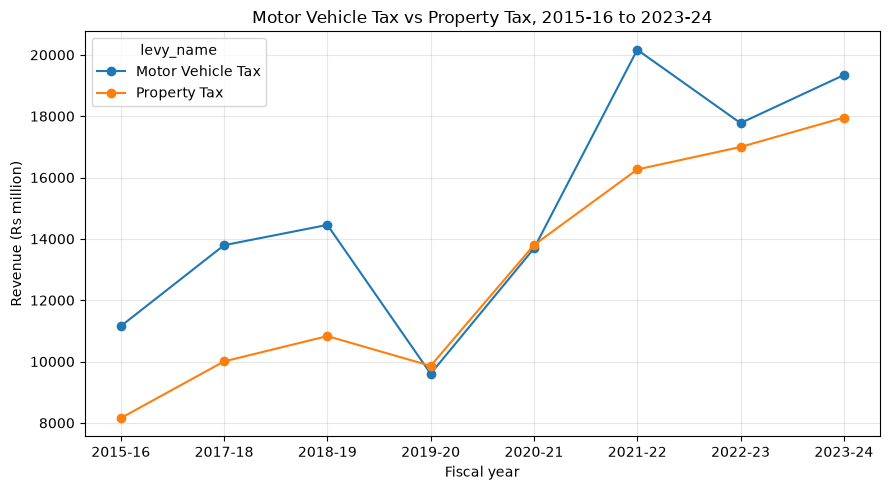

In [51]:
pivot[["Motor Vehicle Tax", "Property Tax"]].plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Motor Vehicle Tax vs Property Tax, 2015-16 to 2023-24")
plt.xlabel("Fiscal year")
plt.ylabel("Revenue (Rs million)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "trend_chart.png"), dpi=150)
plt.show()

## 5. How concentrated is the tax base? (share of total revenue)

**What it does:**
1. `pivot.sum(axis=1)` adds each row across the levies, giving the total revenue per year.
2. `pivot.div(total, axis=0) * 100` divides every levy by that year's total, giving a percentage.
3. Adding the Motor Vehicle Tax and Property Tax columns gives the share of the two largest levies.

**Excel equivalent:** each cell divided by its row's Grand Total.
**Example:** the toy share table above (levy A was 33.3% of the 2022 total).

**What to look for:** two levies supply 83% to 90% of all revenue.

In [52]:
share = pivot.div(pivot.sum(axis=1), axis=0) * 100

print("Share of the two largest levies (%)")
print((share["Motor Vehicle Tax"] + share["Property Tax"]).round(1))
print()
print("Share of Excise Duty (%)")
print(share["Excise Duty"].round(1))

Share of the two largest levies (%)
fiscal_year
2015-16    84.1
2017-18    83.2
2018-19    83.4
2019-20    85.0
2020-21    88.3
2021-22    90.3
2022-23    88.8
2023-24    85.9
dtype: float64

Share of Excise Duty (%)
fiscal_year
2015-16    11.6
2017-18    12.1
2018-19    11.9
2019-20    10.3
2020-21     7.4
2021-22     5.8
2022-23     6.7
2023-24     9.3
Name: Excise Duty, dtype: float64


**Stacked bar chart.** Smaller levies are grouped into one bar called "All other levies" so that the chart stays readable.
- `share[main].copy()` takes only the three main columns (`copy` makes an independent table).
- `share.drop(columns=main).sum(axis=1)` adds up all the other levies.
- `stacked=True` stacks the bars so each one reaches 100%.

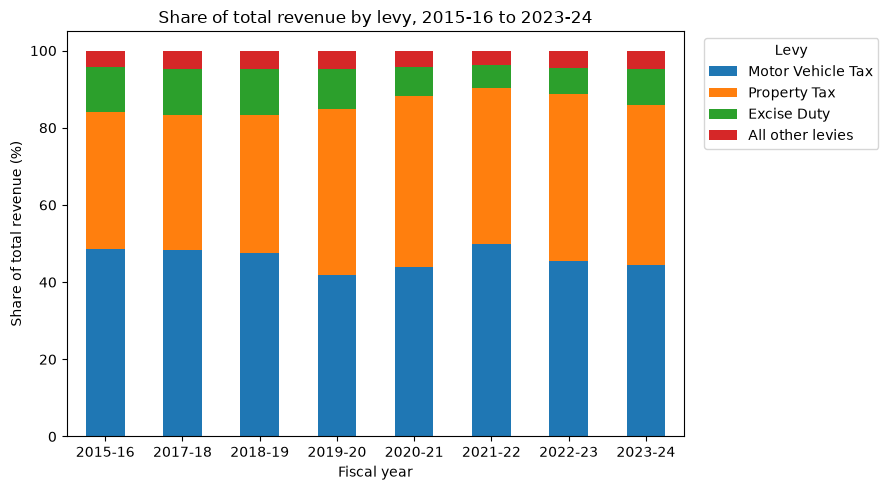

In [53]:
main = ["Motor Vehicle Tax", "Property Tax", "Excise Duty"]
chart = share[main].copy()
chart["All other levies"] = share.drop(columns=main).sum(axis=1)

chart.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Share of total revenue by levy, 2015-16 to 2023-24")
plt.xlabel("Fiscal year")
plt.ylabel("Share of total revenue (%)")
plt.xticks(rotation=0)
plt.legend(title="Levy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "share_chart.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Year-on-year growth

**What it does:** `pct_change()` compares each year with the year before: (this year - last year) / last year, times 100.

**Excel equivalent:** `=(C3-C2)/C2` copied down.
**Example:** toy levy A: 10 to 12 is +20%.

**Important:** 2016-17 is missing, so the 2017-18 row would really be a two-year change. We drop it (and the first row, which has no previous year) before charting.

**What to look for:** in 2019-20 Motor Vehicle Tax and Excise Duty fell by about a third while Property Tax fell by 9%. The levies recover at different speeds.

In [54]:
big = pivot[["Motor Vehicle Tax", "Property Tax", "Excise Duty"]]
growth = big.pct_change() * 100
growth.round(1)

levy_name,Motor Vehicle Tax,Property Tax,Excise Duty
fiscal_year,,,
2015-16,NaN,NaN,NaN
2017-18,23.7,22.6,30.4
2018-19,4.8,8.2,4.4
2019-20,-33.6,-9.0,-34.9
2020-21,42.5,40.0,-1.5
2021-22,47.3,17.9,1.6
2022-23,-11.9,4.5,10.8
2023-24,8.8,5.6,55.6


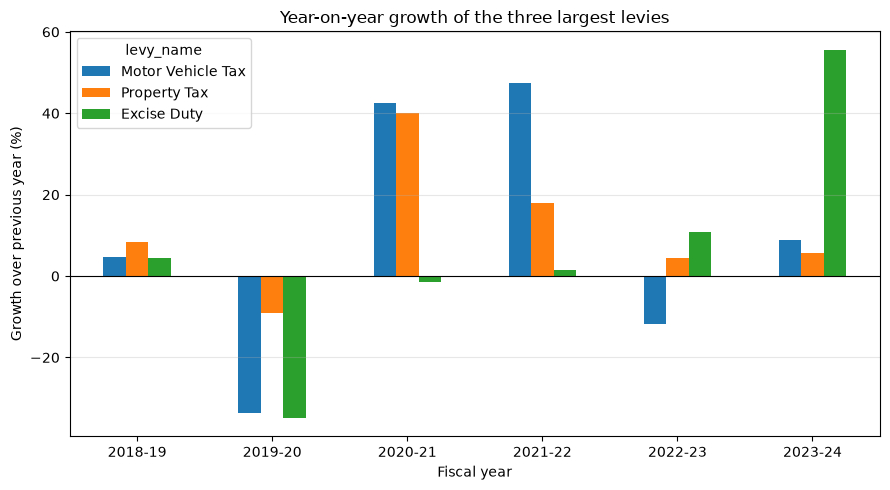

In [55]:
growth.drop(index=["2015-16", "2017-18"]).plot(kind="bar", figsize=(9, 5))
plt.axhline(0, color="black", linewidth=0.8)   # zero line: above = growth, below = fall
plt.title("Year-on-year growth of the three largest levies")
plt.xlabel("Fiscal year")
plt.ylabel("Growth over previous year (%)")
plt.xticks(rotation=0)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "growth_chart.png"), dpi=150)
plt.show()

## 7. How accurate are the revenue targets?

**What it does:**
1. *Achievement %* = collected / target x 100. It is already a column in the file.
2. `describe()` gives count, average, standard deviation (`std`), minimum and maximum in one command. A large `std` means the outcome is unpredictable.
3. *Target uplift %* = target / last year's actual collection - 1. It shows how much higher (or lower) than last year the target was set.

**Excel equivalent:** a pivot of the achievement column, plus `=C2/D2-1`.
**Example:** last year 100, target 130, collected 91 -> uplift +30%, achievement 70%.

**What to look for:** Excise Duty swings the most (about 33% to 109%). In 2019-20 all three levies had their worst year. Targets are close to actual collection in normal years.

In [56]:
big3 = rev[rev["levy_name"].isin(["Motor Vehicle Tax", "Property Tax", "Excise Duty"])].copy()

print("Achievement against target (%)")
print(big3.pivot_table(index="fiscal_year", columns="levy_name",
                       values="achievement_vs_target_%").round(1))

Achievement against target (%)
levy_name    Excise Duty  Motor Vehicle Tax  Property Tax
fiscal_year                                              
2015-16            100.0               99.6          94.2
2017-18            105.5              101.1          98.0
2018-19             94.5              100.1          99.5
2019-20             33.0               60.6          68.6
2020-21             74.4              105.0          95.6
2021-22            108.0              105.5          98.6
2022-23             97.1               96.9          97.1
2023-24            109.0              100.5          98.6


In [57]:
big3.groupby("levy_name")["achievement_vs_target_%"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
levy_name,,,,,,,,
Excise Duty,8.0,90.2,25.6,33.0,89.5,98.5,106.1,109.0
Motor Vehicle Tax,8.0,96.2,14.6,60.6,98.9,100.3,102.1,105.5
Property Tax,8.0,93.8,10.3,68.6,95.2,97.6,98.6,99.5


In [58]:
big3["target_uplift_%"] = (big3["target_rs_million"] / big3["achieved_prev_year_rs_million"] - 1) * 100

print("Target compared with last year's actual collection (%)")
print(big3.pivot_table(index="fiscal_year", columns="levy_name",
                       values="target_uplift_%").round(1))

Target compared with last year's actual collection (%)
levy_name    Excise Duty  Motor Vehicle Tax  Property Tax
fiscal_year                                              
2015-16             46.4               15.7          17.9
2017-18             21.0               10.4          10.5
2018-19             10.5                4.7           8.7
2019-20             97.6                9.6          32.6
2020-21             32.3               35.7          46.5
2021-22             -5.9               39.7          19.6
2022-23             14.2               -9.0           7.6
2023-24             42.7                8.3           7.2


## 8. District-wise vehicle registrations

Vehicle registrations are used as a **proxy** for economic activity in each district. They are not tax revenue.

**What it does:**
- `groupby("district")[...].mean()` averages each district's quarterly registrations.
- `sort_values(ascending=False)` sorts from largest to smallest (Excel: Sort Largest to Smallest).
- `avg / avg.sum() * 100` turns the averages into percentage shares.
- `pd.concat([top, bottom])` stacks the five largest and five smallest districts for the chart.
- `.iloc[::-1]` reverses the order, because a horizontal bar chart draws the first item at the bottom.

**What to look for:** Lahore alone is about a quarter of registrations, and the top five districts are about half.

In [59]:
veh = pd.read_csv(os.path.join(DATA, "02_District_Vehicle_Registration_long.csv"))
print(veh.shape)

avg = veh.groupby("district")["total_vehicles_registered"].mean().sort_values(ascending=False)
share_d = avg / avg.sum() * 100

result = pd.DataFrame({"avg_per_quarter": avg.round(0), "share_%": share_d.round(2)})
print(result.head(5))
print(result.tail(5))
print("Share of the top 5 districts (%):", round(share_d.head(5).sum(), 1))

EmptyDataError: No columns to parse from file

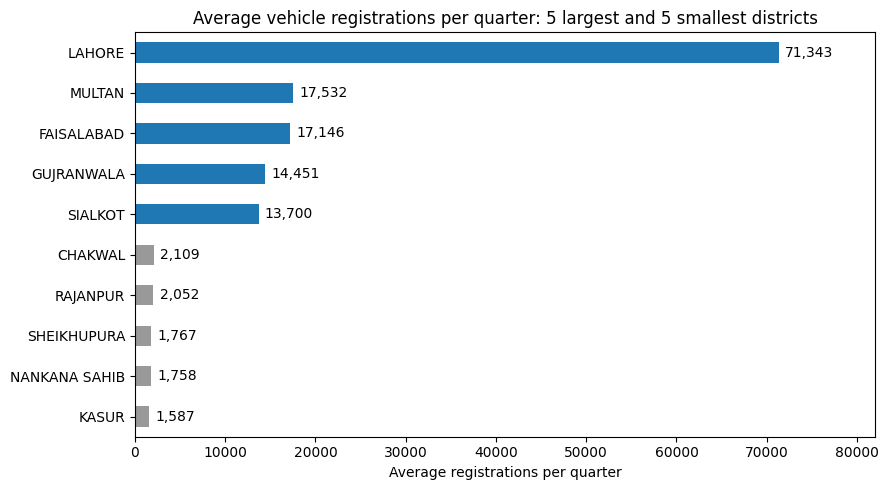

In [ ]:
pick = pd.concat([avg.head(5), avg.tail(5)])
colors = ["#1f77b4"] * 5 + ["#999999"] * 5
pick = pick.iloc[::-1]
colors = colors[::-1]

pick.plot(kind="barh", color=colors, figsize=(9, 5))
plt.title("Average vehicle registrations per quarter: 5 largest and 5 smallest districts")
plt.xlabel("Average registrations per quarter")
plt.ylabel("")
plt.xlim(0, pick.max() * 1.15)
for i, v in enumerate(pick):                 # write the number at the end of each bar
    plt.text(v + 700, i, f"{v:,.0f}", va="center")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "district_chart.png"), dpi=150)
plt.show()

## 9. A simple forecasting baseline

**Goal:** forecast the province-wide number of registrations per quarter and check honestly whether the model is any good.

**Step 9a: build the quarterly table.**
1. `groupby("quarter", sort=False)...sum()` adds the 36 districts for each quarter (`sort=False` keeps the original order).
2. `str.extract` pulls the year and the fiscal quarter number out of the quarter's name (see the toy example in section 1).
3. `map(calendar_q)` converts fiscal quarters to calendar quarters, because the fiscal year starts in July: Q1 = Jul-Sep = calendar quarter 3, Q2 = 4, Q3 = 1, Q4 = 2. A *dictionary* `{key: value}` is a lookup table.
4. `t` is a time counter: the first quarter is 0 and it grows by 1 for every real calendar quarter. Where quarters are missing, `t` jumps (for example 0 to 4), so the model knows about the gaps.

In [ ]:
q = veh.groupby("quarter", sort=False)["total_vehicles_registered"].sum().reset_index()
q.columns = ["quarter", "total"]

q["year"] = q["quarter"].str.extract(r"(\d{4}) \(")[0].astype(int)
q["fq"] = q["quarter"].str.extract(r"Q(\d)\)")[0].astype(int)

calendar_q = {1: 3, 2: 4, 3: 1, 4: 2}
q["qnum"] = q["year"] * 4 + q["fq"].map(calendar_q) - 1
q["t"] = q["qnum"] - q["qnum"].min()

print(q[["quarter", "total", "fq", "t"]])
print("Span in quarters:", q["t"].max() + 1, "| quarters we have:", len(q))

                      quarter   total  fq   t
0   Jul-Sep 2021 (FY21-22 Q1)  351797   1   0
1   Jul-Sep 2022 (FY22-23 Q1)  286521   1   4
2   Oct-Dec 2022 (FY22-23 Q2)  243931   2   5
3   Jan-Mar 2023 (FY22-23 Q3)  291848   3   6
4   Apr-Jun 2023 (FY22-23 Q4)  245434   4   7
5   Oct-Dec 2023 (FY23-24 Q2)  244362   2   9
6   Jan-Mar 2024 (FY23-24 Q3)  312876   3  10
7   Apr-Jun 2024 (FY23-24 Q4)  248319   4  11
8   Jul-Sep 2024 (FY24-25 Q1)  249943   1  12
9   Oct-Dec 2024 (FY24-25 Q2)  259673   2  13
10  Apr-Jun 2025 (FY24-25 Q4)  339345   4  15
Span in quarters: 16 | quarters we have: 11


**Step 9b: fit a model and test it on data it has not seen.**

The model is a straight-line trend (`t`) plus a seasonal adjustment for each fiscal quarter. It is called *linear regression*, and `np.linalg.lstsq` finds the best-fitting numbers (*Excel equivalent:* a trendline, or `LINEST`).

- `make_X` builds the numbers the model needs for each quarter: a constant, the time `t`, and 0/1 columns saying whether the quarter is fiscal Q2, Q3 or Q4 (Q1 is the baseline, when all three are 0).
- **Train / test split:** the first 8 quarters teach the model, and the last 3 are hidden and used only to check the predictions. This is called a *backtest*.
- `@` multiplies the table of inputs by the fitted numbers to give predictions.

In [ ]:
def make_X(df):
    X = pd.DataFrame({"const": 1.0, "t": df["t"].astype(float)})
    for k in [2, 3, 4]:
        X["fq" + str(k)] = (df["fq"] == k).astype(float)
    return X.values

train = q.iloc[:-3]
test = q.iloc[-3:]

coef, *_ = np.linalg.lstsq(make_X(train), train["total"].values, rcond=None)
pred = make_X(test) @ coef

actual = test["total"].values
pd.DataFrame({"quarter": test["quarter"].values, "actual": actual, "model": pred.round(0)})

,quarter,actual,model
0,Jul-Sep 2024 (FY24-25 Q1),249943,293577.0
1,Oct-Dec 2024 (FY24-25 Q2),259673,228797.0
2,Apr-Jun 2025 (FY24-25 Q4),339345,231527.0


**Step 9c: compare with two trivial rules (benchmarks).**

A model is only useful if it beats very simple rules:
- *Last value:* "next quarter will be the same as the previous observed quarter".
- *Training average:* "next quarter will be the average of the training quarters".

If the model cannot beat these, it adds nothing yet.

In [ ]:
last_value = q["total"].shift(1).iloc[-3:].values
train_avg = train["total"].mean()

print("Model MAPE (%)        :", round(mape(actual, pred), 1))
print("Last value MAPE (%)   :", round(mape(actual, last_value), 1))
print("Training average MAPE :", round(mape(actual, train_avg), 1))

Model MAPE (%)        : 20.4
Last value MAPE (%)   : 9.3
Training average MAPE : 12.1


**Step 9d: forecast the next two quarters.** The model is refitted on all 11 quarters. Here `t = 16` is Jul-Sep 2025 (fiscal Q1) and `t = 17` is Oct-Dec 2025 (fiscal Q2). Those quarters have already ended, so the forecasts can later be checked against the department's disclosures.

In [ ]:
coef_all, *_ = np.linalg.lstsq(make_X(q), q["total"].values, rcond=None)
future = pd.DataFrame({"t": [16, 17], "fq": [1, 2]})
print("Forecast for Jul-Sep 2025 and Oct-Dec 2025:", (make_X(future) @ coef_all).round(0))

Forecast for Jul-Sep 2025 and Oct-Dec 2025: [287991. 243250.]


## 10. Results and limits

| Question | Result |
|---|---|
| Is revenue volatile? | Yes. In 2019-20 Motor Vehicle Tax fell 33.6%, Excise Duty 34.9% and Property Tax 9.0%. Motor Vehicle Tax fell again in 2022-23 (-11.9%). |
| Do levies recover together? | No. In 2020-21 and 2021-22 Motor Vehicle Tax grew 42.5% and 47.3%, Excise Duty stayed flat, then grew 55.6% in 2023-24. |
| Are targets reliable? | In normal years targets for the two largest levies were close to actual collection. Excise Duty is unreliable (33.0% to 109.0% achieved), and all three levies fell well short in 2019-20. |
| How narrow is the tax base? | Two levies supply 83% to 90% of revenue (peak 90.3% in 2021-22, 85.9% in 2023-24). |
| Is registration activity concentrated? | Lahore is 25.5% of average quarterly registrations and the top five districts are 48.0%. |
| Can a simple model forecast registrations? | Not yet. Backtest error was 20.4%, worse than repeating the last value (9.3%) or the training average (12.1%). |

**Limits**
- Revenue is available only as yearly totals (eight points per levy, 2016-17 not yet included).
- The vehicle series has 11 of 16 quarters, and registrations are a proxy for district activity, not revenue.
- Two published reports contain inconsistencies (the 2019-20 report prints its comparison columns in reverse order, and the 2022-23 comparison column does not match the 2021-22 report), so growth is always recalculated from the achieved amounts.
- The next step is monthly, gap-free data, which would allow ARIMA or Prophet and a fair comparison with the department's own target errors.

**Practice ideas:** (1) add the 2016-17 achieved amounts to the revenue file and rerun sections 3 to 6; (2) repeat section 7 for Professional Tax; (3) change the train/test split to the last 2 quarters and see how the errors move.